# Pilot Study: Sizing the Connectome-Degradation Sweep (Study 2b: draw count)

Companion to `pilot_degradation_power_analysis.ipynb` (2a: region x repetition, given
one connectome per severity) -- this one sizes the *other* axis: how many
independently-corrupted connectomes ("draws") are needed at a given degradation
severity for a stable `wCSET`-vs-`CSET` comparison. Same independence assumption as
2a's notebook explains: these are two separate pilots, not one joint 3-way model, so
combine this notebook's draw-count recommendation with 2a's `(k, r)` by taking the more
conservative of the two.

**Role-swap from every other pilot**: here `connectome draw` plays the role `region`
normally plays (the top-level random "group"/"subject"), and `region`/`repetition` are
pooled together into a single `pseudo_rep` replicate index nested within each draw --
their own individual contributions aren't the object of study in this notebook (that's
2a's job), just noise to average over. Model: `outcome ~ C(method) + (1|draw) +
(0+C(method)|draw) + (1|draw:pseudo_rep)`, fit separately per severity level -- exactly
the same shape and reasoning as every other pilot's model, just with the group/vc roles
reassigned.

**No new simulation needed.** Reuses a *subset* of `sub-simf10-pilot`'s existing runs
(all 26 regions x the first 3 of 8 repetitions = 78 runs) -- smaller than 2a's full 208,
since this pilot's cost scales with `n_percentages x n_draws` reconstructions per run
instead of just `n_percentages`.

**Severity levels**: `[20, 40, 60, 80, 100]` -- **`percentage=0` is excluded** here
(unlike 2a): every "draw" at zero corruption is identical (no-op), so draw-to-draw
variance is trivially zero and degenerate for this fit. 2a already covers
`percentage=0` on its own.

**Draws per severity**: 5 in the pilot itself (`n_repeats=5`, matching
`sabotage_connectome.ipynb`'s own existing default) -- the grid below sweeps *candidate*
draw counts well beyond that (same principle as every other pilot's `(k, r)` grid
including values larger than what the pilot itself collected: the Monte Carlo simulates
new synthetic data under the fitted variance components for any candidate count, not
just the one the pilot happened to use).

**Companion script**:
- `pilot_degradation_draws_02_solve.py` -- brutal-corrupts 5 draws x 5 severities,
  caches eigenspectra, solves the 78-run subset under all 50 conditions

## 🧬 - Running the pilot (run separately first)

`pilot_degradation_draws_02_solve.py` verifies data integrity, brutal-corrupts 5
independent draws at each of the 5 non-zero severity levels (25 connectomes total),
caches their eigenspectra via `cache_cst_batch`, then solves the 78-run subset (26
regions x repetitions 1-3) under `wCSET`/`CSET` x all 25 `(severity, draw)` pairs --
same `build_phase_data_hrp_pp_curve`/`score_source_reconstruction` scoring as the other
pilots, with each checkpoint row tagged `method`/`percentage`/`draw` as separate
columns. Checkpointed per run (`pilot_degradation_draws_metrics/run-{run:03d}.json` +
`_curves.npz`), same crash-recovery behavior as the other pilots' solve scripts.

Run it before executing the cells below.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

import mindmap as mm

dm = mm.io.TutoManager("../../config.yml")
sub_pilot = "simf10-pilot"

METRICS_DIR = Path("pilot_degradation_draws_metrics")
OUTCOMES = ["localization_error_hrp", "ap_hrp", "ap_pp", "correlation_auc"]
METHODS = ["wcset", "cset"]
PERCENTAGES = [20, 40, 60, 80, 100]
M = len(METHODS)

## 📊 - Aggregate outcome measures

Same three outcome measures per `(region, repetition, percentage, draw, method)` as
the solve script wrote them. `method`/`percentage`/`draw` are already columns in each
checkpoint row, so `load_pilot_checkpoints` only needs to pull `region`/`repetition`
from the run index -- then `region`/`repetition` are combined into one `pseudo_rep`
replicate tag, since their individual contributions aren't the object of study here.

In [2]:
df_index = pd.read_csv(dm.roots["sim"] / f"sub-{sub_pilot}" / "simulation_index.tsv", sep="\t")

df = mm.analysis.power.load_pilot_checkpoints(df_index, METRICS_DIR, index_cols=("region", "repetition"))
df["pseudo_rep"] = df["region"].astype(str) + "_" + df["repetition"].astype(str)

print(f"Aggregated {len(df)} (region,repetition,percentage,draw,method) rows "
      f"({df['run'].nunique()} runs x {df['method'].nunique()} methods x "
      f"{df['percentage'].nunique()} severities x {df['draw'].nunique()} draws x "
      f"{df['pseudo_rep'].nunique()} pooled region x repetition replicates).")
df.to_csv("pilot_degradation_draws_outcomes.tsv", sep="\t", index=False)
df.head()

Aggregated 3900 (region,repetition,percentage,draw,method) rows (78 runs x 2 methods x 5 severities x 5 draws x 78 pooled region x repetition replicates).


,run,method,percentage,draw,localization_error_hrp,ap_hrp,ap_pp,correlation_auc,region,repetition,pseudo_rep
0,1,wcset,20,0,0.000000,0.559915,0.922567,0.308595,ctx-rh-posteriorcingulate_2,1,ctx-rh-posteriorcingulate_2_1
1,1,cset,20,0,0.000000,0.609087,0.897493,0.355836,ctx-rh-posteriorcingulate_2,1,ctx-rh-posteriorcingulate_2_1
2,1,wcset,20,1,0.000000,0.546862,0.926560,0.305589,ctx-rh-posteriorcingulate_2,1,ctx-rh-posteriorcingulate_2_1
3,1,cset,20,1,0.000000,0.562766,0.895557,0.359268,ctx-rh-posteriorcingulate_2,1,ctx-rh-posteriorcingulate_2_1
4,1,wcset,20,2,2.536524,0.558844,0.920033,0.309719,ctx-rh-posteriorcingulate_2,1,ctx-rh-posteriorcingulate_2_1


## 📊 - Fit mixed-effects models, extract variance components (per severity level)

`group_col="draw"` (not `region` -- see intro) + named variance components
`method_draw` (`sigma2(method x draw)`, the effect of primary interest here: does
relative method performance depend on which particular corrupted connectome you
happened to draw, beyond the average severity effect) and `pseudo_rep`
(region-x-repetition-within-draw, pooled) -- refit separately per severity level via
the unmodified `fit_variance_components`.

In [3]:
variance_components = {}   # {percentage: {outcome: {...}}}

for pct in PERCENTAGES:
    df_pct = df[df["percentage"] == pct]
    variance_components[str(pct)] = {}
    for outcome in OUTCOMES:
        vc = mm.analysis.power.fit_variance_components(
            df_pct, outcome,
            group_col="draw", fixed_col="method",
            vc_formula={"method_draw": "0 + C(method)", "pseudo_rep": "0 + C(pseudo_rep)"},
            fixed_levels=METHODS,
        )
        variance_components[str(pct)][outcome] = {
            "sigma2_draw": vc["sigma2_draw"],
            "sigma2_method_draw": vc["sigma2_method_draw"],
            "sigma2_pseudo_rep": vc["sigma2_pseudo_rep"],
            "sigma2_resid": vc["sigma2_resid"],
            "method_means": vc["condition_means"],
        }

with open("pilot_degradation_draws_variance_components.json", "w") as f:
    json.dump(variance_components, f, indent=2)

pd.concat(
    {pct: pd.DataFrame(variance_components[pct]).T[
        ["sigma2_draw", "sigma2_method_draw", "sigma2_pseudo_rep", "sigma2_resid"]
    ] for pct in variance_components},
    names=["percentage", "outcome"],
)

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 15.091647
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


... (18 outputs left out)

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


sigma2_draw sigma2_method_draw  \
percentage outcome                                                 
20         localization_error_hrp   27.522712           6.055566   
           ap_hrp                    0.000392           0.000002   
           ap_pp                     0.000151                0.0   
           correlation_auc           0.000152           0.000385   
40         localization_error_hrp    0.577106             0.0124   
           ap_hrp                    0.000273           0.000005   
           ap_pp                     0.000037           0.000003   
           correlation_auc           0.000287           0.000027   
60         localization_error_hrp   35.376526           3.853057   
           ap_hrp                    0.000012           0.000007   
           ap_pp                          0.0           0.000002   
           correlation_auc           0.000108           0.000003   
80         localization_error_hrp    8.837691           2.811875   
           ap_hrp                    0.000089           0.000001   
           ap_pp                     0.000025                0.0   
           correlation_auc           0.000009           0.000006   
100        localization_error_hrp      0.6805           4.503949   
           ap_hrp                         0.0                0.0   
           ap_pp                      0.00001                0.0   
           correlation_auc            0.00001           0.000001   

                                  sigma2_pseudo_rep sigma2_resid  
percentage outcome                                                
20         localization_error_hrp         46.911412    195.21583  
           ap_hrp                          0.018804      0.00188  
           ap_pp                           0.008477     0.000631  
           correlation_auc                 0.001811     0.002194  
40         localization_error_hrp          99.44871   202.667755  
           ap_hrp                          0.018577     0.001479  
           ap_pp                           0.009117     0.000409  
           correlation_auc                 0.002694     0.001573  
60         localization_error_hrp         94.999324   244.805649  
           ap_hrp                          0.017805     0.000788  
           ap_pp                           0.010457     0.000196  
           correlation_auc                 0.003177     0.000714  
80         localization_error_hrp        231.301615   282.039874  
           ap_hrp                          0.020049     0.000282  
           ap_pp                           0.012629     0.000049  
           correlation_auc                 0.002009     0.000327  
100        localization_error_hrp        186.005161   318.462822  
           ap_hrp                          0.021068     0.000068  
           ap_pp                           0.014965     0.000024  
           correlation_auc                 0.000295      0.00005

## 🎯 - Simulate power/precision curves across a `(k, r)` grid, per severity level

Same Monte Carlo split-plot ANOVA as the other pilots
(`mindmap.core.power.simulate_splitplot_power`), roles reassigned: `k` = candidate
**draw counts** (what this notebook is actually sizing -- kept modest, since each draw
costs a full eigendecomposition, ~18-150s per the sabotage-connectome study's own
timing), `r` = candidate **pooled region x repetition replicate counts** per draw (not
this notebook's job to size -- cross-check against 2a's own `(k, r)` recommendation
rather than tuning it here).

In [4]:
N_SIM = 2000
ALPHA = 0.05
k_grid = [3, 5, 8, 10, 15, 20]      # candidate draw counts
r_grid = [10, 26, 50, 78, 100, 150]  # candidate pooled region x repetition replicate counts

power_results = {}       # {percentage: {outcome: {"condition": ..., "interaction": ...}}}
precision_results = {}   # {percentage: {outcome: ...}}

for pi, pct in enumerate(PERCENTAGES):
    power_results[pct] = {o: {"condition": np.zeros((len(k_grid), len(r_grid))),
                               "interaction": np.zeros((len(k_grid), len(r_grid)))}
                           for o in OUTCOMES}
    precision_results[pct] = {o: np.zeros(len(r_grid)) for o in OUTCOMES}

    for oi, outcome in enumerate(OUTCOMES):
        vc = variance_components[str(pct)][outcome]
        for i, k in enumerate(k_grid):
            for j, r in enumerate(r_grid):
                seed = pi * 1_000_000 + oi * 100_000 + i * 1000 + j
                pm, pw = mm.core.simulate_splitplot_power(
                    condition_means=vc["method_means"],
                    sigma2_group=vc["sigma2_draw"],
                    sigma2_interaction=vc["sigma2_method_draw"],
                    sigma2_rep=vc["sigma2_pseudo_rep"],
                    sigma2_resid=vc["sigma2_resid"],
                    k=k, r=r, m=M, n_sim=N_SIM, alpha=ALPHA, seed=seed,
                )
                power_results[pct][outcome]["condition"][i, j] = pm
                power_results[pct][outcome]["interaction"][i, j] = pw
        for j, r in enumerate(r_grid):
            precision_results[pct][outcome][j] = mm.core.precision_of_mean(
                vc["sigma2_pseudo_rep"], vc["sigma2_resid"], r, M,
            )
    print(f"Power grid done for percentage={pct}")

np.savez(
    "pilot_degradation_draws_power_results.npz", k_grid=k_grid, r_grid=r_grid, percentages=PERCENTAGES,
    **{f"pct{pct}_{o}_method": power_results[pct][o]["condition"] for pct in PERCENTAGES for o in OUTCOMES},
    **{f"pct{pct}_{o}_interaction": power_results[pct][o]["interaction"] for pct in PERCENTAGES for o in OUTCOMES},
    **{f"pct{pct}_{o}_precision": precision_results[pct][o] for pct in PERCENTAGES for o in OUTCOMES},
)

Power grid done for percentage=20


Power grid done for percentage=40


Power grid done for percentage=60


Power grid done for percentage=80


Power grid done for percentage=100


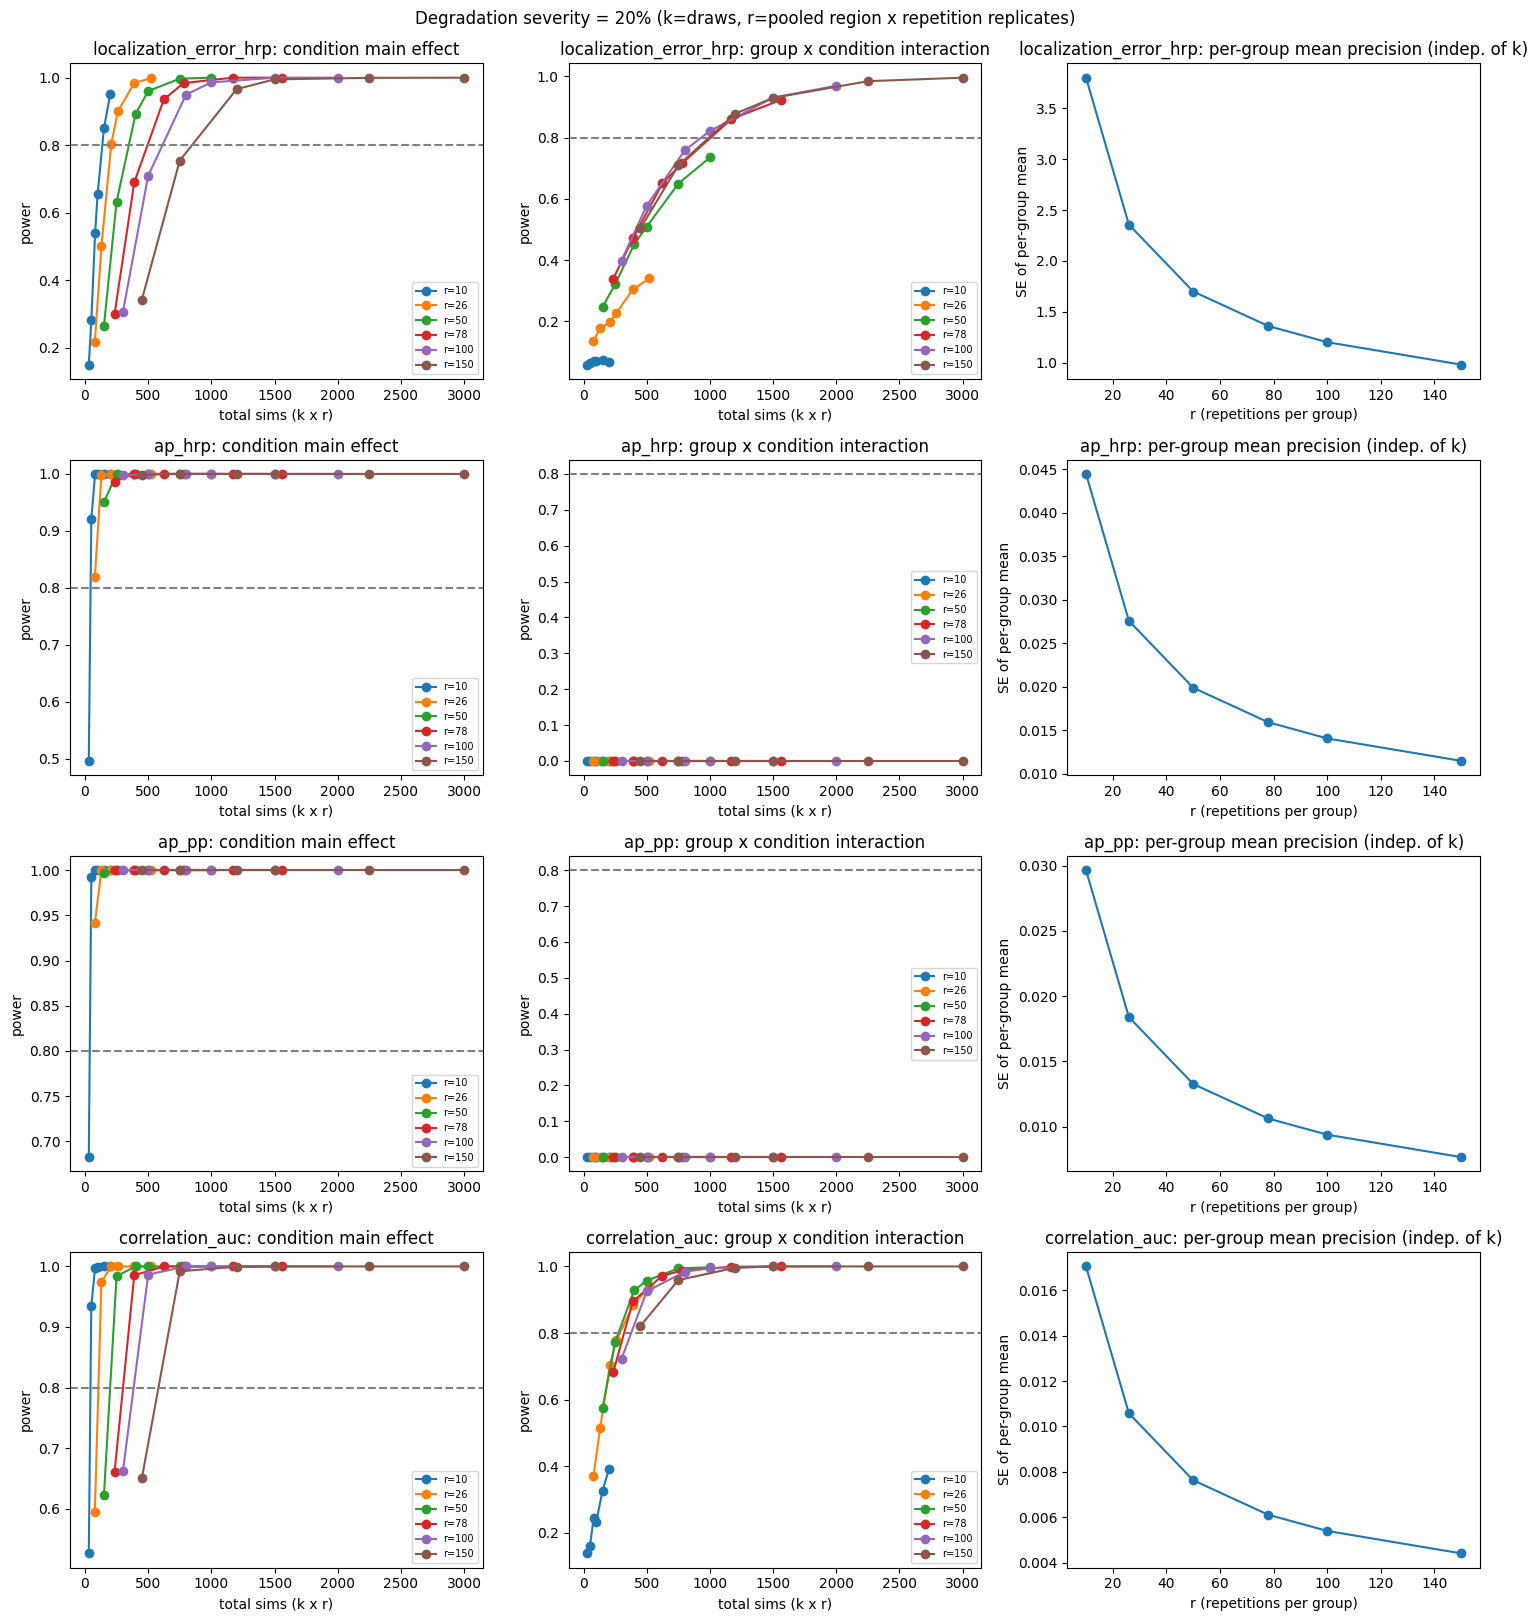

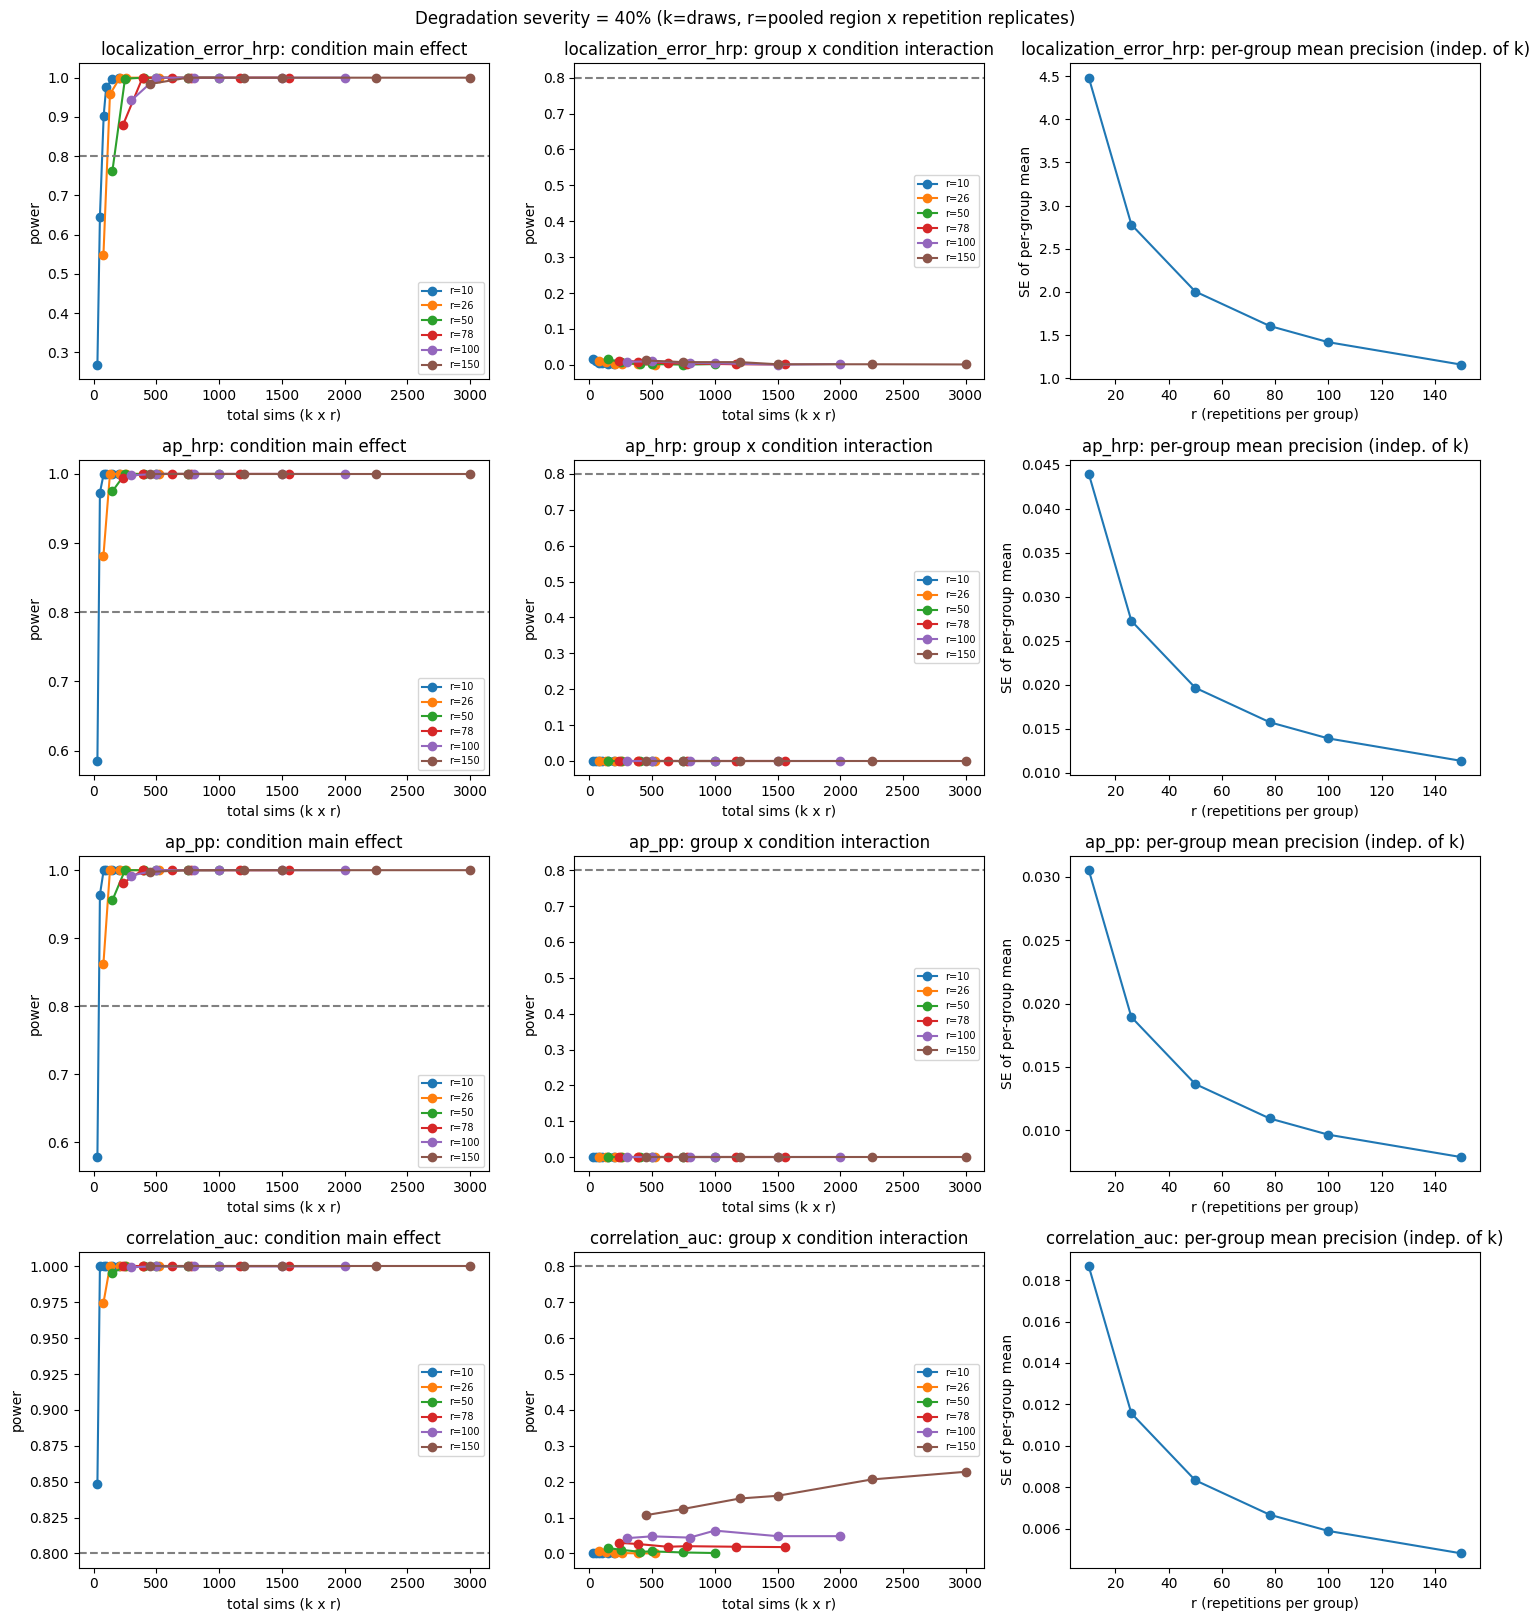

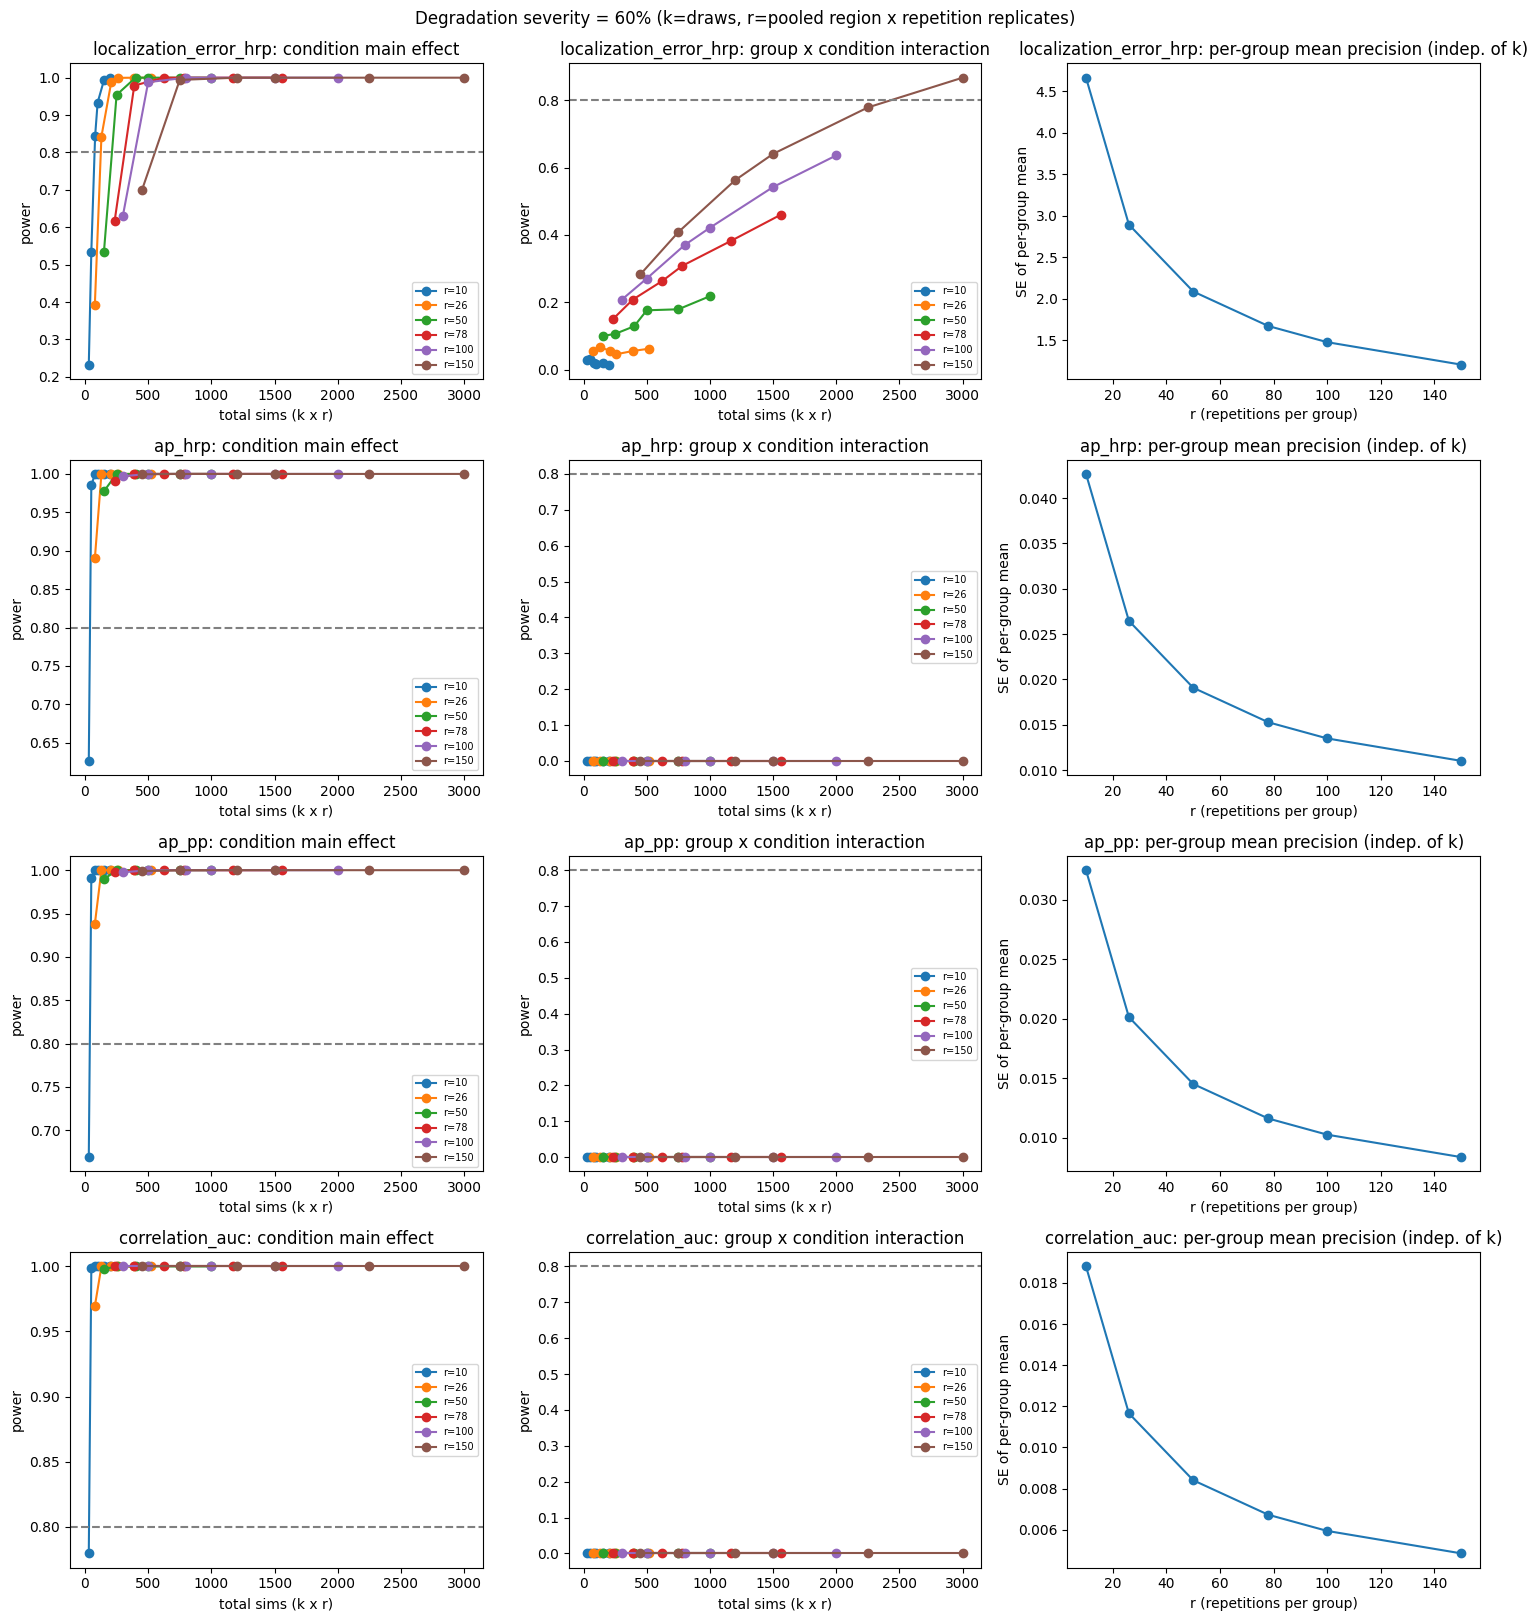

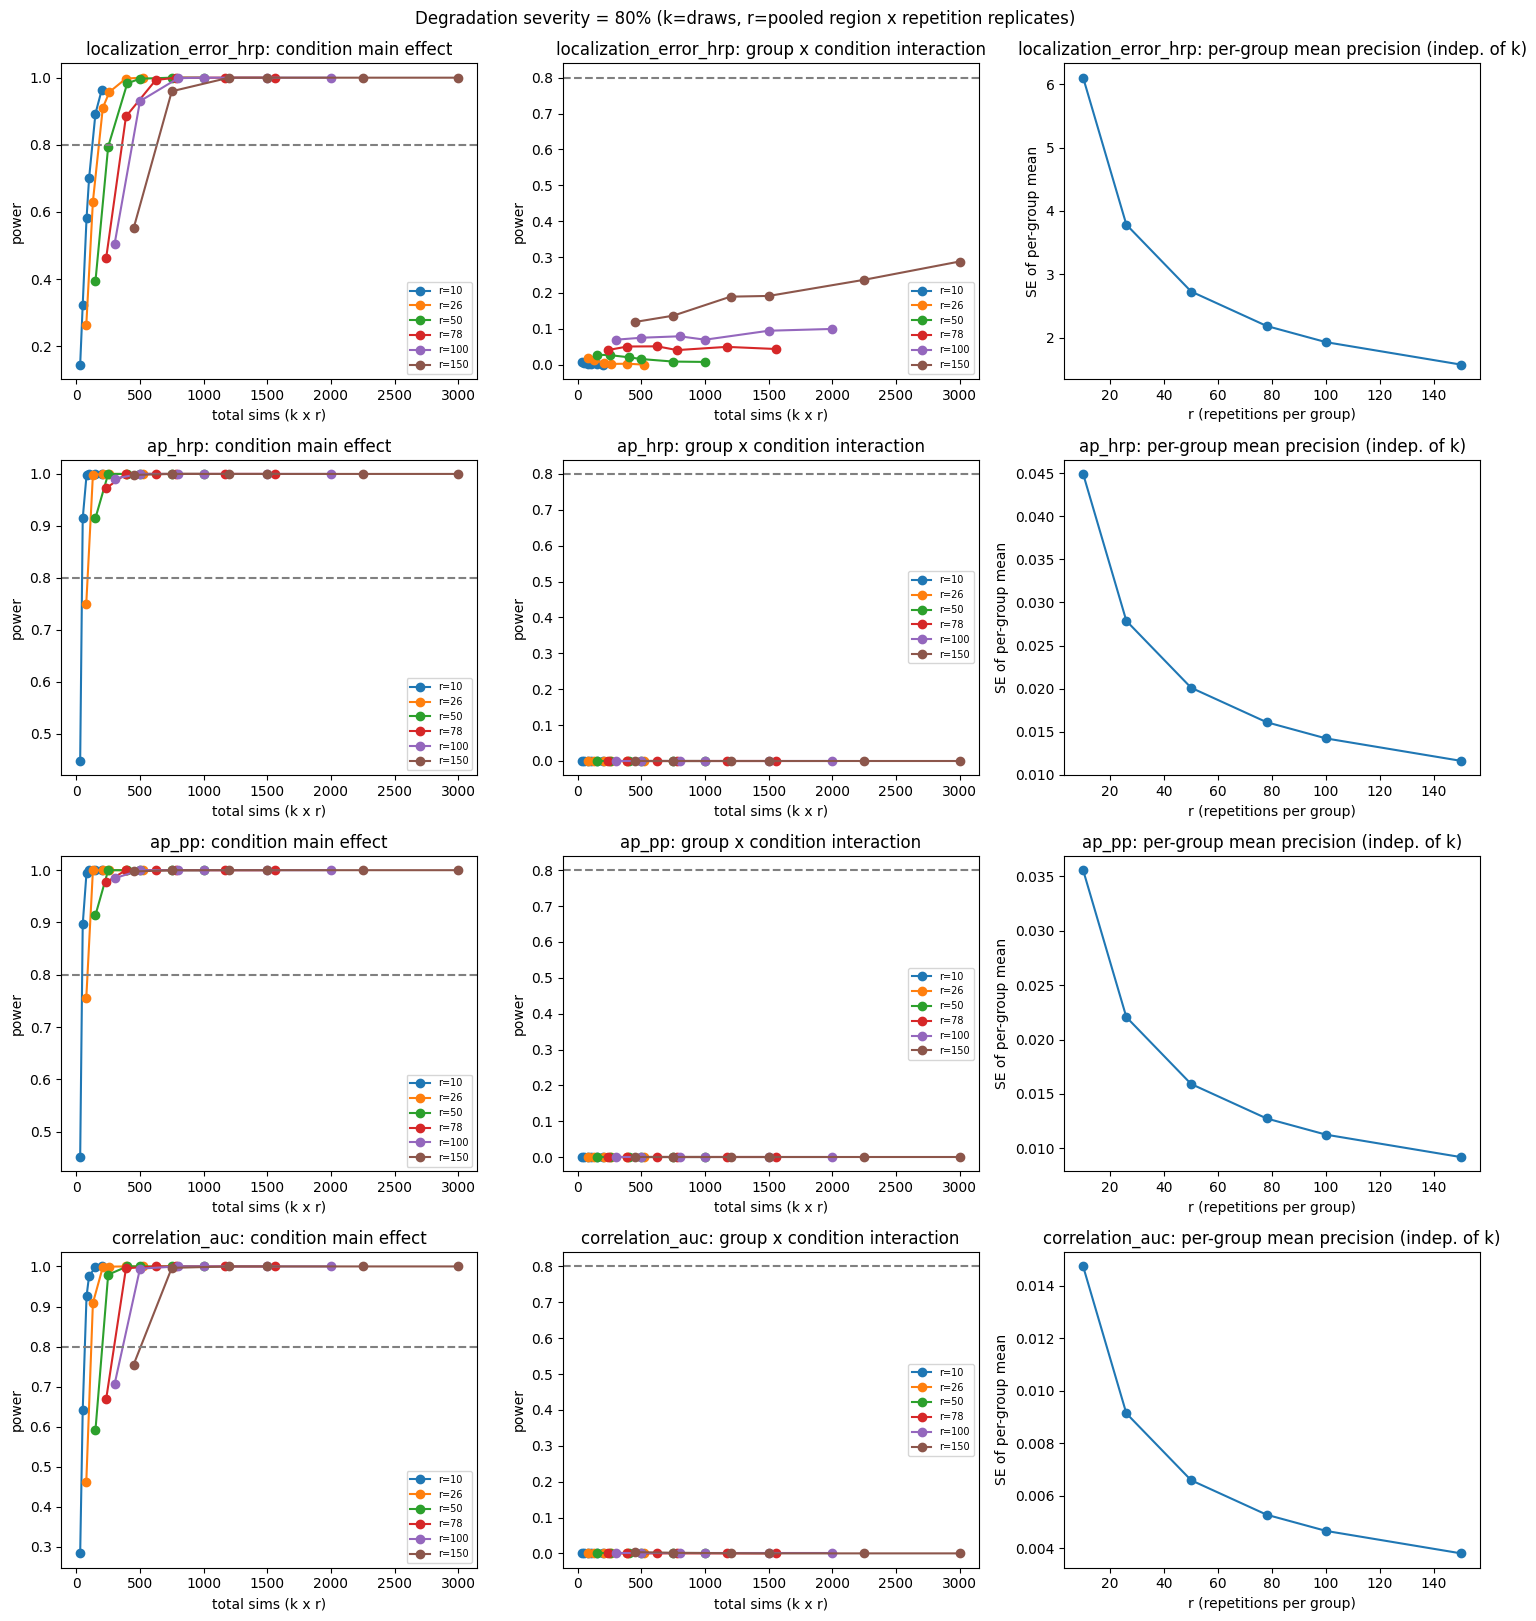

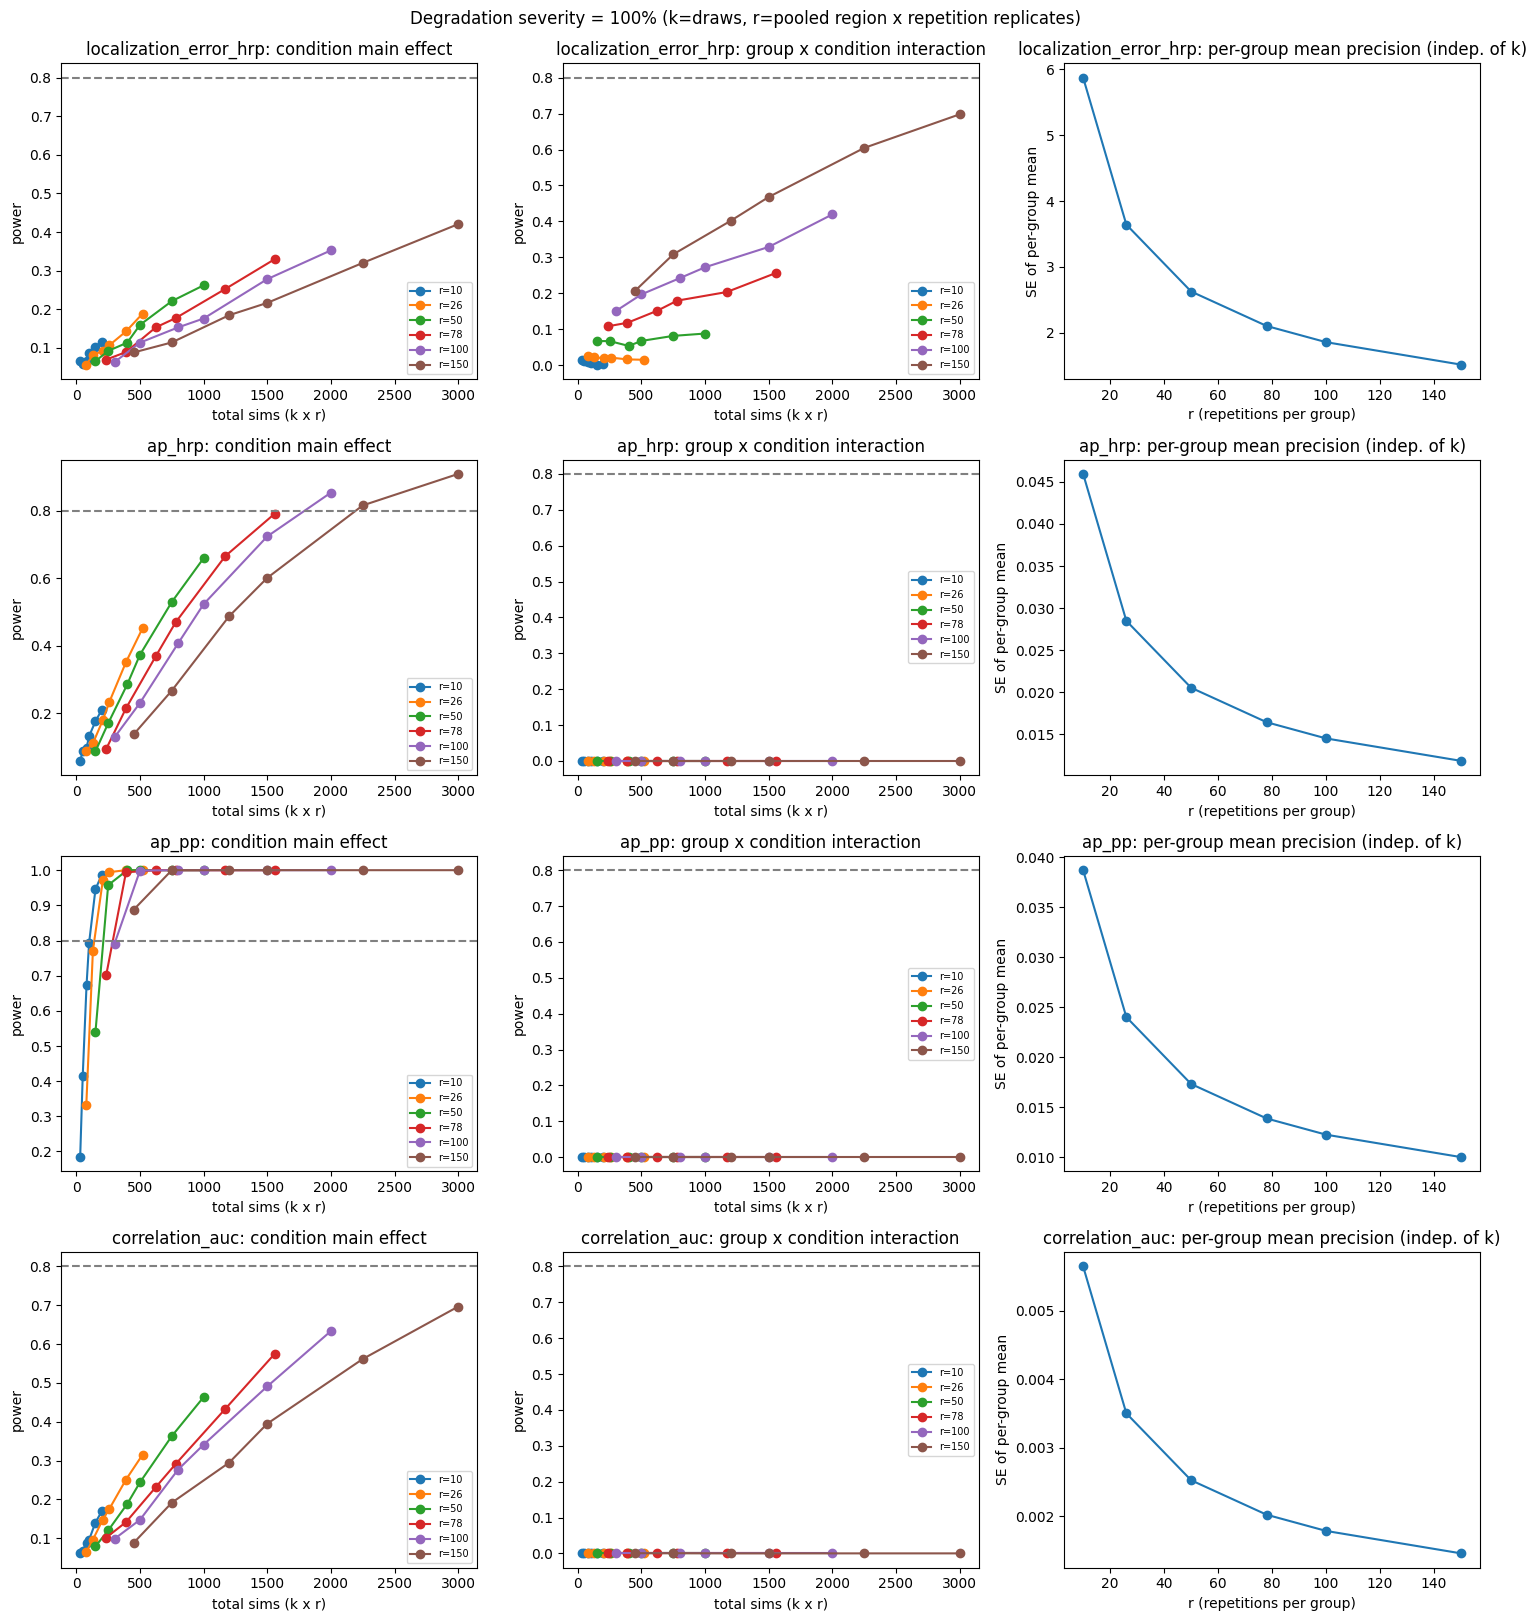

In [5]:
for pct in PERCENTAGES:
    fig = mm.viz.plot_power_precision_curves(power_results[pct], precision_results[pct], k_grid, r_grid, OUTCOMES)
    fig.suptitle(f"Degradation severity = {pct}% (k=draws, r=pooled region x repetition replicates)", y=1.01)
    fig.savefig(f"pilot_degradation_draws_power_curves_pct{pct}.png", dpi=130)

## ✅ - Recommendation (draw count, given a fixed region x repetition pool)

Sized to the worst `(outcome, percentage, test)` combination across the whole grid.
`k` in this output is the **draw-count** recommendation; `r` is the pooled
region x repetition count that recommendation assumed -- cross-check that `r` against
`pilot_degradation_power_analysis.ipynb`'s own `(k_regions, r_reps)` recommendation
(`r` here should be in the same ballpark as `k_regions * r_reps` there). If the two
disagree substantially, that's the independence assumption between region- and
draw-variability showing its limits -- prefer the larger/more conservative implied
sample size.

In [6]:
def worst_case_power(power_results, test):
    worst = np.ones((len(k_grid), len(r_grid)))
    for pct in PERCENTAGES:
        for outcome in OUTCOMES:
            worst = np.minimum(worst, power_results[pct][outcome][test])
    return worst

worst_condition = worst_case_power(power_results, "condition")
worst_interaction = worst_case_power(power_results, "interaction")

THRESHOLD = 0.8
for name, worst in [("condition (main effect)", worst_condition), ("interaction (method x draw)", worst_interaction)]:
    ok = worst >= THRESHOLD
    if not ok.any():
        print(f"{name}: no (k, r) in this grid reaches {THRESHOLD} power across every outcome/percentage -- extend the grid.")
        continue
    total_sims = np.array(k_grid)[:, None] * np.array(r_grid)[None, :]
    candidates = np.where(ok, total_sims, np.inf)
    i, j = np.unravel_index(np.argmin(candidates), candidates.shape)
    print(f"{name}: smallest design clearing {THRESHOLD} power everywhere -- "
          f"k={k_grid[i]} draws, r={r_grid[j]} pooled region x repetition replicates "
          f"(worst-case power={worst[i, j]:.3f}, total sims/method={k_grid[i]*r_grid[j]}).")

condition (main effect): no (k, r) in this grid reaches 0.8 power across every outcome/percentage -- extend the grid.
interaction (method x draw): no (k, r) in this grid reaches 0.8 power across every outcome/percentage -- extend the grid.
